
# Job Board Applications Analysis
### Data Analytics Case Study | July – September 2026

## Business Context

A student-focused job board wants to understand its application funnel, recruitment sources and employer response times.

The objective is to analyse three months of application data and provide actionable insights to support the next month's recruitment strategy.

## Business Questions

1. Which acquisition source generates the highest number of hires per 100 applications? Does performance vary across role categories?
2. Are applicants who complete all four application steps shortlisted more often than applicants who complete fewer steps?
3. How quickly do applicants receive their first response for paid versus unpaid roles? What proportion never receives a response?

## Analytical Approach

- Data loading and inspection
- Data cleaning and preprocessing
- Exploratory Data Analysis (EDA)
- Recruitment source conversion analysis
- Application completion and shortlisting analysis
- Employer response-time analysis
- Data visualisation
- Business recommendations

## Tools and Libraries

Python, Pandas, NumPy, Matplotlib and Seaborn.


## Import libraries

In [1]:

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

# Visualization settings
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11

print("Libraries imported successfully.")


Libraries imported successfully.


## Load the dataset

In [2]:

# Load dataset
df = pd.read_csv("job-board-applications.csv")

# Display initial records
display(df.head())

print("Dataset loaded successfully.")
print("Original shape:", df.shape)


,application_id,applied_on,role_category,work_mode,stipend_inr_month,source,steps_done,shortlisted,interviewed,hired,days_to_first_reply
0,A100010,01-07-2026,Software,on_site,30000,search,2,no,no,no,1.00
1,A100017,01-07-2026,Design,hybrid,0,search,2,no,no,no,9.00
2,A100102,01-07-2026,Operations,hybrid,0,search,0,no,no,no,3.00
3,A100319,01-07-2026,Marketing,remote,15000,search,4,no,no,no,4.00
4,A100394,01-07-2026,Software,on_site,10000,search,4,yes,no,no,2.00


Dataset loaded successfully.
Original shape: (1206, 11)


## Initial data inspection

In [3]:

# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Column information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include='all').T)

# Missing values
print("\nMissing Values:")
missing_values = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().mean() * 100).round(2)
})

display(missing_values)

# Duplicate records
print("\nExact duplicate rows:", df.duplicated().sum())

# Duplicate application IDs
print("Duplicate application IDs:",
      df['application_id'].duplicated().sum())


Rows: 1206
Columns: 11

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1206 entries, 0 to 1205
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   application_id       1206 non-null   object 
 1   applied_on           1206 non-null   object 
 2   role_category        1206 non-null   object 
 3   work_mode            1206 non-null   object 
 4   stipend_inr_month    1206 non-null   int64  
 5   source               1191 non-null   object 
 6   steps_done           1206 non-null   int64  
 7   shortlisted          1206 non-null   object 
 8   interviewed          1206 non-null   object 
 9   hired                1206 non-null   object 
 10  days_to_first_reply  970 non-null    float64
dtypes: float64(1), int64(2), object(8)
memory usage: 103.8+ KB

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
application_id,1206,1200,A100227,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
applied_on,1206,92,17-08-2026,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN
role_category,1206,6,Software,382,NaN,NaN,NaN,NaN,NaN,NaN,NaN
work_mode,1206,6,remote,509,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stipend_inr_month,1206.00,NaN,NaN,NaN,11199.83,12195.19,0.00,0.00,8000.00,20000.00,40000.00
source,1191,5,search,441,NaN,NaN,NaN,NaN,NaN,NaN,NaN
steps_done,1206.00,NaN,NaN,NaN,2.51,1.37,0.00,1.00,3.00,4.00,4.00
shortlisted,1206,2,no,936,NaN,NaN,NaN,NaN,NaN,NaN,NaN
interviewed,1206,2,no,1031,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hired,1206,2,no,1142,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing Values:


,Missing Count,Missing Percentage
application_id,0,0.00
applied_on,0,0.00
role_category,0,0.00
work_mode,0,0.00
stipend_inr_month,0,0.00
source,15,1.24
steps_done,0,0.00
shortlisted,0,0.00
interviewed,0,0.00
hired,0,0.00



Exact duplicate rows: 6
Duplicate application IDs: 6


## Data cleaning and preprocessing

In [4]:

# Create a working copy
data = df.copy()

# 1. Remove exact duplicate records
original_rows = len(data)

data = data.drop_duplicates().copy()

duplicates_removed = original_rows - len(data)

# 2. Convert application dates
data['applied_on'] = pd.to_datetime(
    data['applied_on'],
    format='%d-%m-%Y',
    errors='coerce'
)

# 3. Standardise categorical columns
categorical_columns = [
    'role_category',
    'work_mode',
    'source',
    'shortlisted',
    'interviewed',
    'hired'
]

for col in categorical_columns:
    data[col] = data[col].astype('string').str.strip()

# Standardise role categories
data['role_category'] = data['role_category'].str.title()

# Standardise work modes
data['work_mode'] = (
    data['work_mode']
    .str.lower()
    .replace({
        'on-site': 'on_site',
        'onsite': 'on_site'
    })
)

# Standardise acquisition sources
data['source'] = data['source'].str.lower()

# Standardise recruitment outcomes
for col in ['shortlisted', 'interviewed', 'hired']:
    data[col] = data[col].str.lower()

# 4. Convert numeric columns
data['stipend_inr_month'] = pd.to_numeric(
    data['stipend_inr_month'],
    errors='coerce'
)

data['steps_done'] = pd.to_numeric(
    data['steps_done'],
    errors='coerce'
)

data['days_to_first_reply'] = pd.to_numeric(
    data['days_to_first_reply'],
    errors='coerce'
)

# 5. Validate date range
data = data[
    data['applied_on'].between(
        pd.Timestamp('2026-07-01'),
        pd.Timestamp('2026-09-30')
    )
].copy()

# 6. Validate numeric fields
assert data['stipend_inr_month'].dropna().ge(0).all()
assert data['steps_done'].dropna().between(0, 4).all()
assert data['days_to_first_reply'].dropna().ge(0).all()

# 7. Create paid/unpaid classification
data['payment_status'] = np.where(
    data['stipend_inr_month'] > 0,
    'Paid',
    'Unpaid'
)

# 8. Create application completion classification
data['completion_status'] = np.where(
    data['steps_done'] == 4,
    'Completed All 4 Steps',
    'Completed Fewer Than 4 Steps'
)

print("DATA CLEANING SUMMARY")
print("---------------------")
print("Original records:", original_rows)
print("Duplicate records removed:", duplicates_removed)
print("Final records:", len(data))
print("Unique application IDs:", data['application_id'].nunique())

print("\nMissing values after cleaning:")
display(data.isnull().sum())

print("\nCleaned dataset:")
display(data.head())


DATA CLEANING SUMMARY
---------------------
Original records: 1206
Duplicate records removed: 6
Final records: 1200
Unique application IDs: 1200

Missing values after cleaning:


application_id           0
applied_on               0
role_category            0
work_mode                0
stipend_inr_month        0
source                  15
steps_done               0
shortlisted              0
interviewed              0
hired                    0
days_to_first_reply    234
payment_status           0
completion_status        0
dtype: int64


Cleaned dataset:


,application_id,applied_on,role_category,work_mode,stipend_inr_month,source,steps_done,shortlisted,interviewed,hired,days_to_first_reply,payment_status,completion_status
0,A100010,2026-07-01,Software,on_site,30000,search,2,no,no,no,1.00,Paid,Completed Fewer Than 4 Steps
1,A100017,2026-07-01,Design,hybrid,0,search,2,no,no,no,9.00,Unpaid,Completed Fewer Than 4 Steps
2,A100102,2026-07-01,Operations,hybrid,0,search,0,no,no,no,3.00,Unpaid,Completed Fewer Than 4 Steps
3,A100319,2026-07-01,Marketing,remote,15000,search,4,no,no,no,4.00,Paid,Completed All 4 Steps
4,A100394,2026-07-01,Software,on_site,10000,search,4,yes,no,no,2.00,Paid,Completed All 4 Steps


## Data quality report

In [5]:

# Check duplicate records
print("Remaining exact duplicates:", data.duplicated().sum())

print("Remaining duplicate application IDs:",
      data['application_id'].duplicated().sum())

# Check date range
print("\nApplication date range:")
print(data['applied_on'].min(), "to", data['applied_on'].max())

# Check categorical values
for col in categorical_columns:
    print(f"\n{col}:")
    print(data[col].value_counts(dropna=False))

# Check recruitment funnel consistency
print("\nHired without interview:",
      ((data['hired'] == 'yes') &
       (data['interviewed'] != 'yes')).sum())

print("Interviewed without shortlisting:",
      ((data['interviewed'] == 'yes') &
       (data['shortlisted'] != 'yes')).sum())

# Check missing values
print("\nMissing source values:",
      data['source'].isna().sum())

print("Missing reply times:",
      data['days_to_first_reply'].isna().sum())


Remaining exact duplicates: 0
Remaining duplicate application IDs: 0

Application date range:
2026-07-01 00:00:00 to 2026-09-30 00:00:00

role_category:
role_category
Software      381
Data          219
Marketing     209
Design        149
Operations    139
Finance       103
Name: count, dtype: Int64

work_mode:
work_mode
remote     511
hybrid     377
on_site    312
Name: count, dtype: Int64

source:
source
search      439
social      257
college     208
email       160
referral    121
<NA>         15
Name: count, dtype: Int64

shortlisted:
shortlisted
no     931
yes    269
Name: count, dtype: Int64

interviewed:
interviewed
no     1025
yes     175
Name: count, dtype: Int64

hired:
hired
no     1136
yes      64
Name: count, dtype: Int64

Hired without interview: 0
Interviewed without shortlisting: 0

Missing source values: 15
Missing reply times: 234


## General application statistics

In [6]:

total_applications = len(data)

total_shortlisted = (data['shortlisted'] == 'yes').sum()

total_interviewed = (data['interviewed'] == 'yes').sum()

total_hired = (data['hired'] == 'yes').sum()

print("GENERAL APPLICATION STATISTICS")

print(f"Total Applications: {total_applications}")
print(f"Shortlisted: {total_shortlisted}")
print(f"Interviewed: {total_interviewed}")
print(f"Total Hired: {total_hired}")

print("\nOverall Conversion Rates")

print(
    "Shortlisting Rate:",
    round(total_shortlisted / total_applications * 100, 2),
    "%"
)

print(
    "Interview Rate:",
    round(total_interviewed / total_applications * 100, 2),
    "%"
)

print(
    "Hiring Rate:",
    round(total_hired / total_applications * 100, 2),
    "%"
)


GENERAL APPLICATION STATISTICS
Total Applications: 1200
Shortlisted: 269
Interviewed: 175
Total Hired: 64

Overall Conversion Rates
Shortlisting Rate: 22.42 %
Interview Rate: 14.58 %
Hiring Rate: 5.33 %


## Applications by role category

,Role Category,Applications
0,Software,381
1,Data,219
2,Marketing,209
3,Design,149
4,Operations,139
5,Finance,103


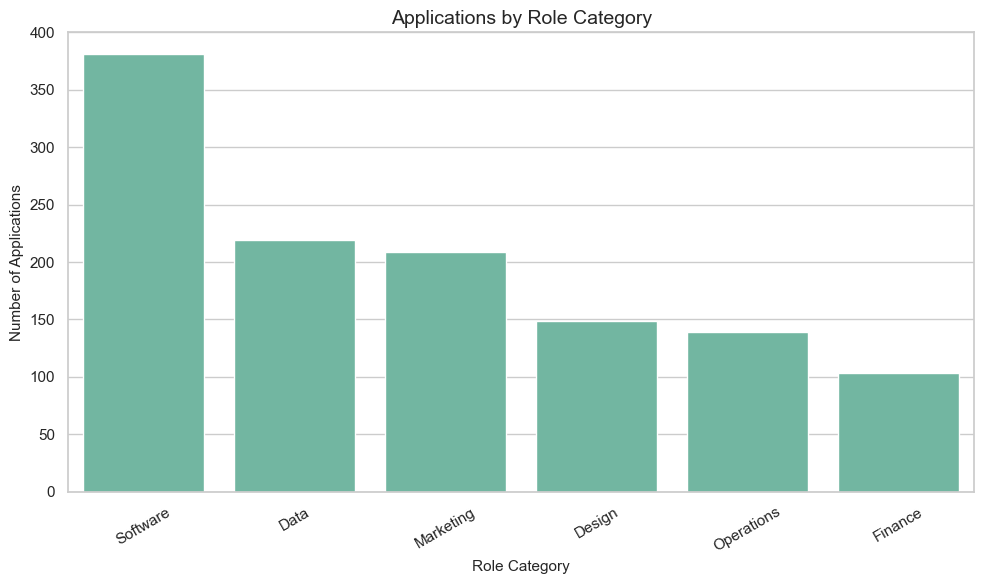

In [7]:

role_distribution = (
    data['role_category']
    .value_counts()
    .reset_index()
)

role_distribution.columns = [
    'Role Category',
    'Applications'
]

display(role_distribution)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=role_distribution,
    x='Role Category',
    y='Applications'
)

plt.title('Applications by Role Category')
plt.xlabel('Role Category')
plt.ylabel('Number of Applications')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


## Applications by acquisition source

,Source,Applications
0,search,439
1,social,257
2,college,208
3,email,160
4,referral,121


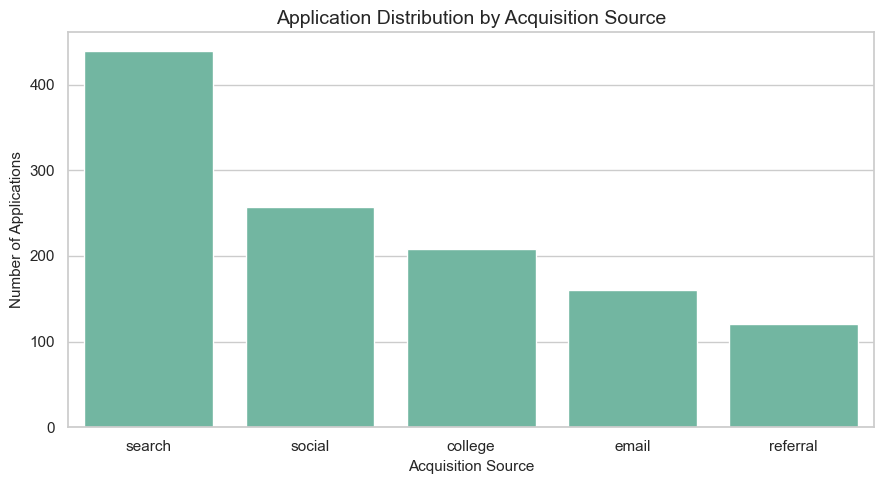

In [8]:

source_distribution = (
    data['source']
    .value_counts()
    .reset_index()
)

source_distribution.columns = [
    'Source',
    'Applications'
]

display(source_distribution)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=source_distribution,
    x='Source',
    y='Applications'
)

plt.title('Application Distribution by Acquisition Source')
plt.xlabel('Acquisition Source')
plt.ylabel('Number of Applications')

plt.tight_layout()
plt.show()


# Business question: Which source brings the most hires per 100 applications? Does the answer hold for each role category?

## Overall source conversion analysis

In [9]:

# Exclude records with missing acquisition source
source_data = data.dropna(subset=['source']).copy()

# Group by acquisition source
source_analysis = (
    source_data.groupby('source')
    .agg(
        Applications=('application_id', 'nunique'),
        Hires=('hired', lambda x: (x == 'yes').sum())
    )
)

# Calculate hires per 100 applications
source_analysis['Hires per 100 Applications'] = (
    source_analysis['Hires'] /
    source_analysis['Applications'] * 100
)

# Sort by conversion rate
source_analysis = source_analysis.sort_values(
    'Hires per 100 Applications',
    ascending=False
)

display(source_analysis.round(2))

# Identify the best-performing source
best_source = source_analysis[
    'Hires per 100 Applications'
].idxmax()

best_rate = source_analysis.loc[
    best_source,
    'Hires per 100 Applications'
]

print(f"\nBest Acquisition Source: {best_source.title()}")
print(f"Hires per 100 Applications: {best_rate:.2f}")


,Applications,Hires,Hires per 100 Applications
source,,,
referral,121,13,10.74
email,160,13,8.12
search,439,25,5.69
college,208,7,3.37
social,257,6,2.33



Best Acquisition Source: Referral
Hires per 100 Applications: 10.74


## Visualisation of hiring effectiveness by source

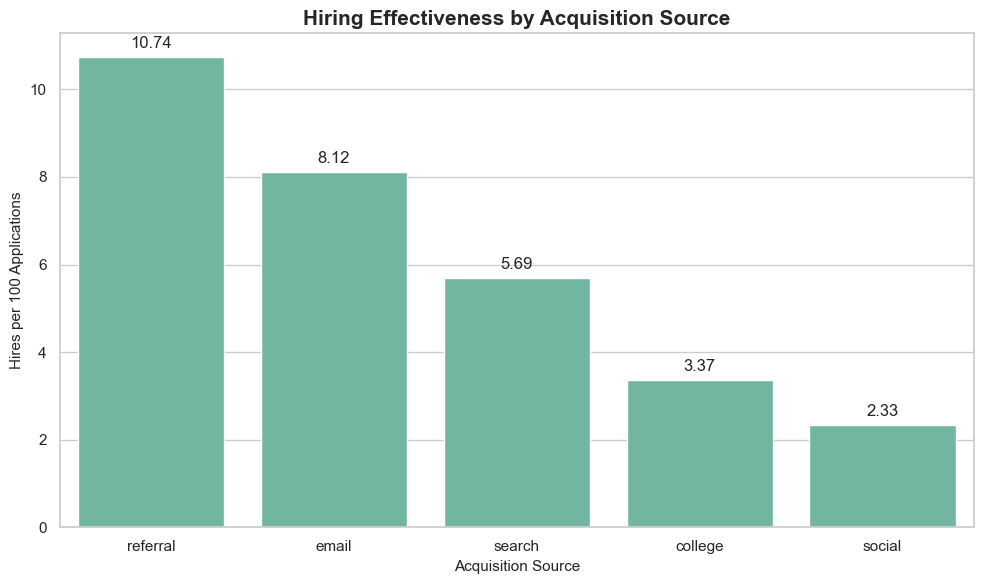

In [10]:

plt.figure(figsize=(10, 6))

plot_data = source_analysis.reset_index()

ax = sns.barplot(
    data=plot_data,
    x='source',
    y='Hires per 100 Applications'
)

# Add values above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f',
        padding=4
    )

plt.title(
    'Hiring Effectiveness by Acquisition Source',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Acquisition Source')
plt.ylabel('Hires per 100 Applications')

plt.tight_layout()
plt.show()


## Source performance across role categories

In [11]:

# Group by role category and acquisition source
role_source_analysis = (
    source_data.groupby(['role_category', 'source'])
    .agg(
        Applications=('application_id', 'nunique'),
        Hires=('hired', lambda x: (x == 'yes').sum())
    )
    .reset_index()
)

# Calculate hiring rate
role_source_analysis['Hire Rate (%)'] = (
    role_source_analysis['Hires'] /
    role_source_analysis['Applications'] * 100
)

# Display complete analysis
display(
    role_source_analysis.sort_values(
        ['role_category', 'Hire Rate (%)'],
        ascending=[True, False]
    ).round(2)
)


,role_category,source,Applications,Hires,Hire Rate (%)
3,Data,search,81,6,7.41
2,Data,referral,21,1,4.76
4,Data,social,45,2,4.44
1,Data,email,33,1,3.03
0,Data,college,34,0,0.00
7,Design,referral,13,3,23.08
8,Design,search,47,5,10.64
6,Design,email,27,2,7.41
5,Design,college,30,2,6.67
9,Design,social,32,1,3.12


## Identify the best source for each role

In [12]:

# Identify the highest conversion source in each role category
best_source_by_role = (
    role_source_analysis
    .sort_values(
        ['role_category', 'Hire Rate (%)', 'Applications'],
        ascending=[True, False, False]
    )
    .groupby('role_category')
    .head(1)
    .reset_index(drop=True)
)

print("BEST ACQUISITION SOURCE BY ROLE CATEGORY")

display(
    best_source_by_role[
        [
            'role_category',
            'source',
            'Applications',
            'Hires',
            'Hire Rate (%)'
        ]
    ].round(2)
)


BEST ACQUISITION SOURCE BY ROLE CATEGORY


,role_category,source,Applications,Hires,Hire Rate (%)
0,Data,search,81,6,7.41
1,Design,referral,13,3,23.08
2,Finance,search,34,1,2.94
3,Marketing,referral,18,4,22.22
4,Operations,college,15,3,20.00
5,Software,email,44,5,11.36


## Heatmap of source effectiveness across roles

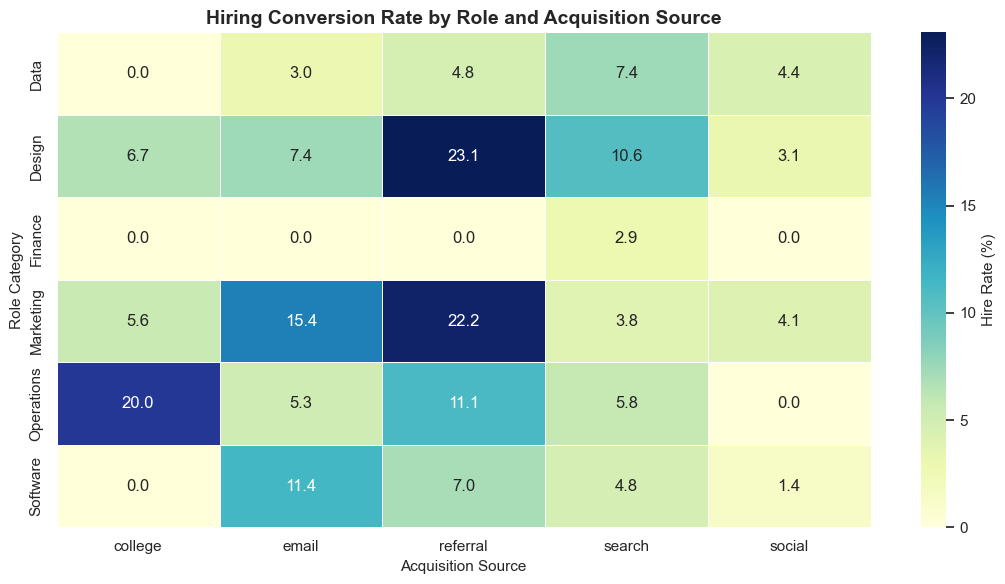

In [13]:

# Create pivot table
heatmap_data = role_source_analysis.pivot(
    index='role_category',
    columns='source',
    values='Hire Rate (%)'
)

plt.figure(figsize=(11, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar_kws={'label': 'Hire Rate (%)'}
)

plt.title(
    'Hiring Conversion Rate by Role and Acquisition Source',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Acquisition Source')
plt.ylabel('Role Category')

plt.tight_layout()
plt.show()


Business interpretation:

Referral leads overall, but it is not the best channel for every role. Recruitment campaigns should use role-specific acquisition strategies rather than relying on a single channel.

Also, some role-source combinations have small application counts. Their rates should be treated as directional findings, not proven long-term performance.

# Business question: Are applicants who finish all four steps shortlisted more often than those who do not? By how much?

## Calculate shortlisting rates

In [14]:

# Group applications by completion status
completion_analysis = (
    data.groupby('completion_status')
    .agg(
        Applications=('application_id', 'nunique'),
        Shortlisted=(
            'shortlisted',
            lambda x: (x == 'yes').sum()
        )
    )
)

# Calculate shortlisting percentage
completion_analysis['Shortlisting Rate (%)'] = (
    completion_analysis['Shortlisted'] /
    completion_analysis['Applications'] * 100
)

display(completion_analysis.round(2))


,Applications,Shortlisted,Shortlisting Rate (%)
completion_status,,,
Completed All 4 Steps,403,195,48.39
Completed Fewer Than 4 Steps,797,74,9.28


## Calculate the difference and relative likelihood

In [15]:

# Extract the two shortlisting rates
completed_rate = completion_analysis.loc[
    'Completed All 4 Steps',
    'Shortlisting Rate (%)'
]

incomplete_rate = completion_analysis.loc[
    'Completed Fewer Than 4 Steps',
    'Shortlisting Rate (%)'
]

# Percentage-point difference
percentage_point_difference = (
    completed_rate - incomplete_rate
)

# Relative likelihood
relative_likelihood = (
    completed_rate / incomplete_rate
)

print("SHORTLISTING COMPARISON")

print(f"Completed all 4 steps: {completed_rate:.2f}%")
print(f"Completed fewer than 4 steps: {incomplete_rate:.2f}%")

print(
    f"Percentage-point difference: "
    f"{percentage_point_difference:.2f}"
)

print(
    f"Relative likelihood: "
    f"{relative_likelihood:.2f} times"
)


SHORTLISTING COMPARISON
Completed all 4 steps: 48.39%
Completed fewer than 4 steps: 9.28%
Percentage-point difference: 39.10
Relative likelihood: 5.21 times


## Visualise shortlisting rates

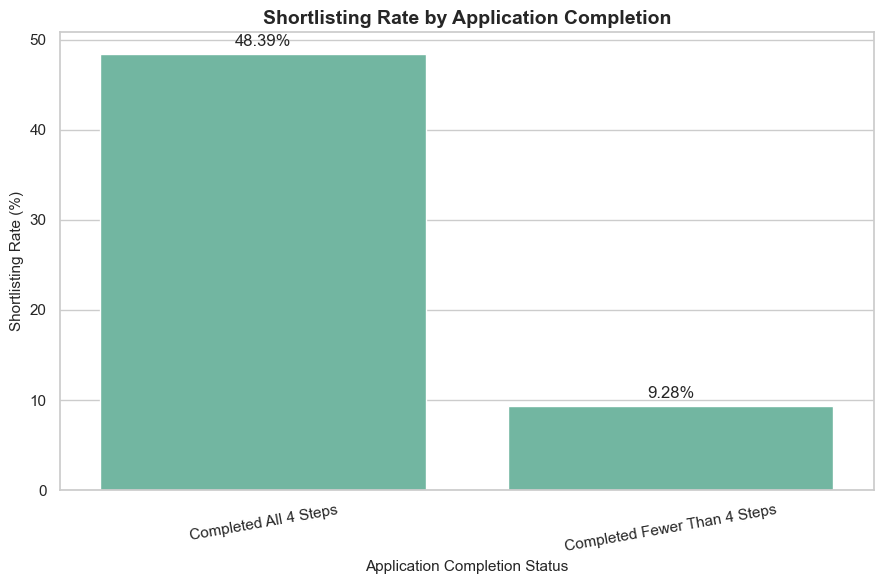

In [16]:

plot_completion = completion_analysis.reset_index()

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=plot_completion,
    x='completion_status',
    y='Shortlisting Rate (%)'
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f%%',
        padding=4
    )

plt.title(
    'Shortlisting Rate by Application Completion',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Application Completion Status')
plt.ylabel('Shortlisting Rate (%)')

plt.xticks(rotation=10)

plt.tight_layout()
plt.show()


Business interpretation:

Applicants who complete all four steps have a substantially higher shortlisting rate.

The difference is 39.10 percentage points, with the completed group having approximately 5.21 times the shortlisting rate.

This supports adding progress indicators, reminders and clear instructions to help applicants finish the application process.

However, this is an association, not proof that completing all four steps causes shortlisting. Applicant quality and other factors may also affect the result.

# Business question: How fast do applicants hear back from paid roles compared with unpaid roles, and what share never hear back?

## Paid and unpaid response analysis

In [17]:

# Group by payment status
response_analysis = (
    data.groupby('payment_status')
    .agg(
        Total_Applications=('application_id', 'nunique'),

        Replies_Received=(
            'days_to_first_reply',
            'count'
        ),

        Never_Replied=(
            'days_to_first_reply',
            lambda x: x.isna().sum()
        ),

        Average_Reply_Days=(
            'days_to_first_reply',
            'mean'
        ),

        Median_Reply_Days=(
            'days_to_first_reply',
            'median'
        ),

        P75_Reply_Days=(
            'days_to_first_reply',
            lambda x: x.quantile(0.75)
        )
    )
)

# Calculate never-replied percentage
response_analysis['Never_Replied (%)'] = (
    response_analysis['Never_Replied'] /
    response_analysis['Total_Applications'] * 100
)

display(response_analysis.round(2))


,Total_Applications,Replies_Received,Never_Replied,Average_Reply_Days,Median_Reply_Days,P75_Reply_Days,Never_Replied (%)
payment_status,,,,,,,
Paid,734,638,96,3.22,3.00,4.00,13.08
Unpaid,466,328,138,7.62,7.00,10.00,29.61


## Compare response-time differences

In [19]:

paid_median = response_analysis.loc[
    'Paid',
    'Median_Reply_Days'
]

unpaid_median = response_analysis.loc[
    'Unpaid',
    'Median_Reply_Days'
]

paid_never = response_analysis.loc[
    'Paid',
    'Never_Replied (%)'
]

unpaid_never = response_analysis.loc[
    'Unpaid',
    'Never_Replied (%)'
]

reply_gap = unpaid_median - paid_median

never_reply_gap = unpaid_never - paid_never

print("PAID VS UNPAID RESPONSE COMPARISON")

print(f"Paid median response: {paid_median:.2f} days")
print(f"Unpaid median response: {unpaid_median:.2f} days")

print(f"\nMedian response-time gap: {reply_gap:.2f} days")

print(f"\nPaid never-replied rate: {paid_never:.2f}%")
print(f"Unpaid never-replied rate: {unpaid_never:.2f}%")

print(
    f"\nNever-replied percentage-point gap: "
    f"{never_reply_gap:.2f}"
)


PAID VS UNPAID RESPONSE COMPARISON
Paid median response: 3.00 days
Unpaid median response: 7.00 days

Median response-time gap: 4.00 days

Paid never-replied rate: 13.08%
Unpaid never-replied rate: 29.61%

Never-replied percentage-point gap: 16.53


## Visualise median response times

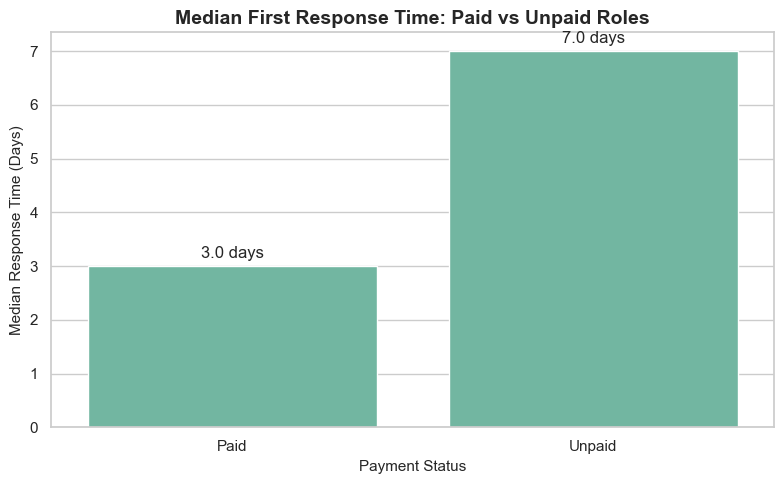

In [20]:

# Prepare data for plotting
response_plot = response_analysis.reset_index()

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=response_plot,
    x='payment_status',
    y='Median_Reply_Days'
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f days',
        padding=4
    )

plt.title(
    'Median First Response Time: Paid vs Unpaid Roles',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Payment Status')
plt.ylabel('Median Response Time (Days)')

plt.tight_layout()
plt.show()


## Visualise the never-replied percentage

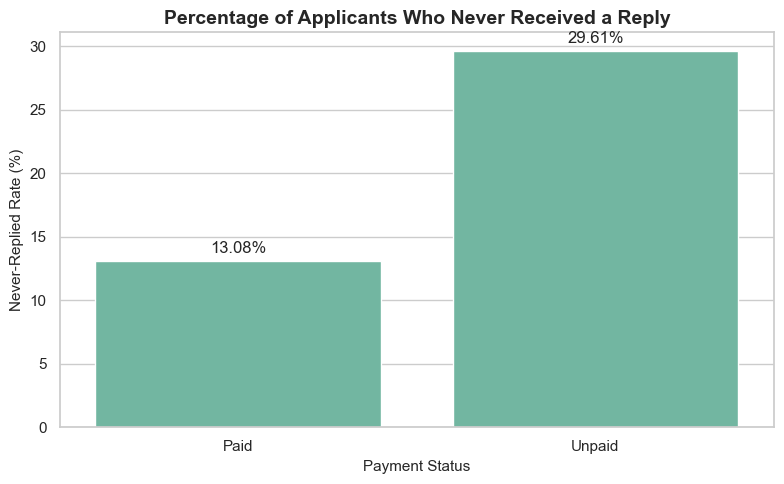

In [21]:

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=response_plot,
    x='payment_status',
    y='Never_Replied (%)'
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f%%',
        padding=4
    )

plt.title(
    'Percentage of Applicants Who Never Received a Reply',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Payment Status')
plt.ylabel('Never-Replied Rate (%)')

plt.tight_layout()
plt.show()


Business interpretation:

Unpaid roles have a median response time of seven days, compared with three days for paid roles.

Furthermore, 29.61% of unpaid-role applicants never receive a recorded reply, compared with 13.08% for paid roles.

This is a substantial difference. The job board should consider introducing response-time expectations for employers and monitoring employers who fail to respond.

One limitation is that the dataset does not provide a separate application closing date or a confirmed observation cutoff for each application. Therefore, blank reply times should be described as no recorded reply, rather than assuming every employer has permanently failed to respond.

# Final business insights

## Consolidated results

In [23]:

print("JOB BOARD APPLICATIONS - FINAL ANALYTICS SUMMARY")

print("\n1. ACQUISITION SOURCE EFFECTIVENESS")

print(
    f"Best overall source: {best_source.title()}"
)

print(
    f"Hires per 100 applications: {best_rate:.2f}"
)

print("\nBest source by role:")

for _, row in best_source_by_role.iterrows():
    print(
        f"{row['role_category']}: "
        f"{row['source'].title()} "
        f"({row['Hire Rate (%)']:.2f}%)"
    )

print("\n2. APPLICATION COMPLETION")

print(
    f"All 4 steps: {completed_rate:.2f}% shortlisted"
)

print(
    f"Fewer than 4 steps: {incomplete_rate:.2f}% shortlisted"
)

print(
    f"Difference: {percentage_point_difference:.2f} "
    f"percentage points"
)

print(
    f"Relative likelihood: {relative_likelihood:.2f}x"
)

print("\n3. EMPLOYER RESPONSE TIME")

print(
    f"Paid roles: {paid_median:.0f} days median response"
)

print(
    f"Unpaid roles: {unpaid_median:.0f} days median response"
)

print(
    f"Response time gap: {reply_gap:.0f} days"
)

print(
    f"Paid never-replied rate: {paid_never:.2f}%"
)

print(
    f"Unpaid never-replied rate: {unpaid_never:.2f}%"
)

JOB BOARD APPLICATIONS - FINAL ANALYTICS SUMMARY

1. ACQUISITION SOURCE EFFECTIVENESS
Best overall source: Referral
Hires per 100 applications: 10.74

Best source by role:
Data: Search (7.41%)
Design: Referral (23.08%)
Finance: Search (2.94%)
Marketing: Referral (22.22%)
Operations: College (20.00%)
Software: Email (11.36%)

2. APPLICATION COMPLETION
All 4 steps: 48.39% shortlisted
Fewer than 4 steps: 9.28% shortlisted
Difference: 39.10 percentage points
Relative likelihood: 5.21x

3. EMPLOYER RESPONSE TIME
Paid roles: 3 days median response
Unpaid roles: 7 days median response
Response time gap: 4 days
Paid never-replied rate: 13.08%
Unpaid never-replied rate: 29.61%


## Generate business recommendations

In [24]:

recommendations = [
    {
        "Area": "Recruitment Sources",
        "Finding": "Referral has the highest overall hiring conversion.",
        "Recommendation": "Increase referral campaigns and tailor channels to each role category."
    },
    {
        "Area": "Application Completion",
        "Finding": "Applicants completing all four steps have a 48.39% shortlisting rate.",
        "Recommendation": "Introduce application progress indicators and completion reminders."
    },
    {
        "Area": "Employer Response",
        "Finding": "Unpaid roles have slower responses and higher non-response rates.",
        "Recommendation": "Set employer response targets and monitor delayed or missing replies."
    }
]

recommendations_df = pd.DataFrame(recommendations)

display(recommendations_df)


,Area,Finding,Recommendation
0,Recruitment Sources,Referral has the highest overall hiring conver...,Increase referral campaigns and tailor channel...
1,Application Completion,Applicants completing all four steps have a 48...,Introduce application progress indicators and ...
2,Employer Response,Unpaid roles have slower responses and higher ...,Set employer response targets and monitor dela...


# Manager's Note (200 words)


Manager's Note: Job Board Application Analysis
**Reporting Period: July – September 2026**

The analysis of 1,200 unique applications highlights three areas for improvement.

**1. Recruitment sources:** Referrals generated the highest hiring conversion, with 10.74 hires per 100 applications, followed by email at 8.13. However, the best source varies by role. Referrals lead in Design and Marketing, while Search leads in Data and Finance, Email in Software, and College in Operations. We should tailor acquisition campaigns to each category rather than use one channel for every role.

**2. Application completion:** Applicants completing all four steps had a 48.39% shortlisting rate, compared with 9.28% for those completing fewer steps. This is a 39.10 percentage-point difference. We should improve completion through progress indicators, clearer instructions and reminders.

**3. Employer response:** Paid roles had a median first-response time of 3 days, compared with 7 days for unpaid roles. The never-replied rates were 13.08% and 29.61%, respectively. This gap is large enough to justify employer response targets and follow-up monitoring.

**Recommendation for next month:** Run targeted referral campaigns, improve the application completion journey, and introduce employer response tracking, with priority given to unpaid listings.

**Data limitations:** Six exact duplicate records were removed, and 15 missing source values were excluded from source comparisons. Another 234 applications had no recorded reply time. Source-level hiring rates also rely on small samples in some role categories. The findings show associations, not causation, and should be validated with future data.


## Export analysis results

In [25]:

output_file = "Job_Board_Analysis_Results.xlsx"

with pd.ExcelWriter(output_file, engine='openpyxl') as writer:

    # Cleaned dataset
    data.to_excel(
        writer,
        sheet_name='Cleaned Data',
        index=False
    )

    # Overall source performance
    source_analysis.to_excel(
        writer,
        sheet_name='Source Analysis'
    )

    # Role-wise source performance
    role_source_analysis.to_excel(
        writer,
        sheet_name='Role Source Analysis',
        index=False
    )

    # Completion analysis
    completion_analysis.to_excel(
        writer,
        sheet_name='Completion Analysis'
    )

    # Response analysis
    response_analysis.to_excel(
        writer,
        sheet_name='Response Analysis'
    )

    # Recommendations
    recommendations_df.to_excel(
        writer,
        sheet_name='Recommendations',
        index=False
    )

print(f"Analysis exported successfully: {output_file}")


Analysis exported successfully: Job_Board_Analysis_Results.xlsx
